# Orbits with JAX and PyTorch

This notebook describes how to integrate orbits with
[JAX](https://docs.jax.dev/) and [PyTorch](https://pytorch.org/) and how to
differentiate them: with respect to their initial conditions and with
respect to the parameters of the potential, in forward and reverse mode, for
single orbits and for batches of orbits. See the [quick
start](../getting_started/backends.ipynb) for an introduction to galpy's backends.

In [1]:
%matplotlib inline
import time

import jax

jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy
import torch

import galpy.backend
from galpy.orbit import Orbit
from galpy.potential import LogarithmicHaloPotential, MWPotential2014, PlummerPotential

ic = [1.0, 0.1, 1.1, 0.1, 0.05, 0.0]  # R,vR,vT,z,vz,phi
ts = numpy.linspace(0.0, 10.0, 101)

## Two ways to integrate an orbit on a backend

An `Orbit` whose initial condition is a JAX array or a PyTorch tensor can be
integrated in two ways:

1. **In the backend**, with the backend's own ODE solver:
   [diffrax](https://docs.kidger.site/diffrax/) for JAX (`method="diffrax"`,
   an eighth-order Dormand-Prince method) and
   [torchode](https://github.com/martenlienen/torchode) or
   [torchdiffeq](https://github.com/rtqichen/torchdiffeq) for PyTorch
   (`method="torchode"` or `method="torchdiffeq"`, a fifth-order
   Dormand-Prince method). The whole integration is then a JAX or PyTorch
   computation, so everything that enters it can be differentiated: the
   initial condition, the parameters of the potential, and the times. It runs
   on a GPU when the initial condition is on a GPU.
2. **With galpy's C integrators**, which are much faster on a CPU but opaque
   to automatic differentiation. When the initial condition is
   differentiated, galpy integrates the variational equations alongside the
   orbit in C and uses the resulting state-transition matrix as the
   derivative of the orbit with respect to its initial condition. This gives
   derivatives with respect to the initial condition only, to first order.

The in-backend integration agrees with the C integrator to the tolerance of
the integrators (the default tolerances are $10^{-12}$):

In [2]:
o = Orbit(jnp.asarray(ic))
o.integrate(ts, MWPotential2014, method="diffrax")
oc = Orbit(ic)
oc.integrate(ts, MWPotential2014, method="dop853_c")
print(type(o.R(ts)))
print("diffrax vs. C:", numpy.max(numpy.fabs(numpy.asarray(o.R(ts)) - oc.R(ts))))

<class 'jaxlib._jax.ArrayImpl'>
diffrax vs. C: 3.7801095587042255e-11


In [3]:
ot = Orbit(torch.tensor(ic, dtype=torch.float64))
ot.integrate(torch.as_tensor(ts), MWPotential2014, method="torchode")
print(type(ot.R(ts)))
print("torchode vs. C:", numpy.max(numpy.fabs(ot.R(ts).numpy() - oc.R(ts))))

<class 'torch.Tensor'>
torchode vs. C: 4.311662138434258e-12


After the integration, the orbit's methods work as usual and return backend
arrays: positions and velocities at the integration times or, through an
in-backend spline, between them, energies, angular momenta, observed
coordinates, pericenters, apocenters, and so on:

In [4]:
print(o.E(ts[-1]), o.Lz(ts[-1]), o.rperi(), o.rap(), o.zmax())

-0.7418820418152644 1.100000000000002 0.9838816729763908 1.326394653211661 0.13061059232058597


Inside a `galpy.backend.use("jax")` (or `"torch"`) block, an `Orbit` set up
from Python floats is a JAX (or PyTorch) orbit, the same as one set up from a
backend array:

In [5]:
with galpy.backend.use("jax"):
    o2 = Orbit(ic)
o2.integrate(ts, MWPotential2014, method="diffrax")
print(type(o2.R(ts)), numpy.max(numpy.fabs(o2.R(ts) - o.R(ts))))

<class 'jaxlib._jax.ArrayImpl'> 0.0


## Derivatives with respect to the initial condition

Any function of an orbit integrated in the backend can be differentiated
with respect to the initial condition. For example, the sensitivity of
$R(t)$ and $z(t)$ to the initial condition, as a function of time, for an
orbit in a Plummer potential, by reverse-mode differentiation with
`jax.jacrev`:

In [6]:
pp = PlummerPotential(amp=1.0, b=0.6)
ts_short = numpy.linspace(0.0, 10.0, 101)


def Rz(ic):
    o = Orbit(ic)
    o.integrate(ts_short, pp, method="diffrax")
    return jnp.stack([o.R(ts_short), o.z(ts_short)])


dRz = jax.jacrev(Rz)(jnp.asarray(ic))
print(dRz.shape)  # (R/z, time, initial condition)

(2, 101, 6)


We compare $\partial R(t)/\partial R_0$, $\partial R(t)/\partial v_{R,0}$,
$\partial z(t)/\partial z_0$, and $\partial z(t)/\partial v_{z,0}$ with
central finite differences of C orbits:

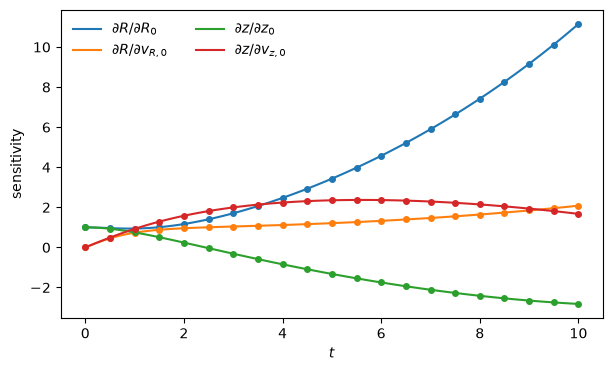

In [7]:
def Rz_c(ic):
    o = Orbit(list(ic))
    o.integrate(ts_short, pp, method="dop853_c")
    return numpy.array([o.R(ts_short), o.z(ts_short)])


h = 1e-6
plt.figure(figsize=(7, 4))
for row, col, label in [
    (0, 0, r"\partial R/\partial R_0"),
    (0, 1, r"\partial R/\partial v_{R,0}"),
    (1, 3, r"\partial z/\partial z_0"),
    (1, 4, r"\partial z/\partial v_{z,0}"),
]:
    e = numpy.zeros(6)
    e[col] = h
    fd = (Rz_c(numpy.array(ic) + e) - Rz_c(numpy.array(ic) - e))[row] / (2.0 * h)
    (line,) = plt.plot(ts_short, dRz[row, :, col], label=rf"${label}$")
    plt.plot(ts_short[::5], fd[::5], "o", color=line.get_color(), ms=4)
plt.xlabel(r"$t$")
plt.ylabel("sensitivity")
plt.legend(frameon=False, ncol=2);

Lines are the automatic derivative, points the finite differences.

With PyTorch, the initial condition is a tensor that requires a gradient:

In [8]:
ict = torch.tensor(ic, dtype=torch.float64, requires_grad=True)
ot = Orbit(ict)
ot.integrate(torch.as_tensor(ts_short), pp, method="torchode")
ot.R(ts_short[-1]).backward()
print(ict.grad)
print(dRz[0, -1])

tensor([1.1152e+01, 2.0819e+00, 2.1453e+01, 9.3785e-01, 1.0917e+00, 7.3452e-12],
       dtype=torch.float64)
[ 1.11521107e+01  2.08188149e+00  2.14529659e+01  9.37854038e-01
  1.09167699e+00 -4.44089210e-16]


## Derivatives with respect to the parameters of the potential

The in-backend integration is also differentiable with respect to the
parameters of the potential. Set up the potential with the parameter inside
the function that you differentiate:

In [9]:
def final_R(b):
    o = Orbit(jnp.asarray(ic))
    o.integrate(ts_short, PlummerPotential(amp=1.0, b=b), method="diffrax")
    return o.R(ts_short[-1])


dRdb = jax.grad(final_R)(0.6)


def final_R_c(b):
    o = Orbit(ic)
    o.integrate(ts_short, PlummerPotential(amp=1.0, b=b), method="dop853_c")
    return o.R(ts_short[-1])


h = 1e-5
print(dRdb, (final_R_c(0.6 + h) - final_R_c(0.6 - h)) / (2.0 * h))

7.6910995843586365 7.691099583606586


With PyTorch, give the parameter as a tensor that requires a gradient:

In [10]:
b = torch.tensor(0.6, dtype=torch.float64, requires_grad=True)
ot = Orbit(torch.tensor(ic, dtype=torch.float64))
ot.integrate(
    torch.as_tensor(ts_short), PlummerPotential(amp=1.0, b=b), method="torchode"
)
ot.R(ts_short[-1]).backward()
print(b.grad)

tensor(7.6911, dtype=torch.float64)


As an example, we fit the flattening $q$ of a logarithmic halo to the $x$
and $z$ coordinates along an orbit, which we generate with $q=0.85$. The
loss function contains the orbit integration and is differentiated and
compiled with `jax.jit(jax.value_and_grad(...))`; after the first call,
which compiles the function, each evaluation is fast:

In [11]:
ts_fit = numpy.linspace(0.0, 5.0, 51)
o_obs = Orbit(ic)
o_obs.integrate(
    ts_fit, LogarithmicHaloPotential(normalize=1.0, q=0.85), method="dop853_c"
)
x_obs, z_obs = o_obs.x(ts_fit), o_obs.z(ts_fit)


def loss(q):
    pot = LogarithmicHaloPotential(normalize=1.0, q=q)
    o = Orbit(jnp.asarray(ic))
    o.integrate(ts_fit, pot, method="diffrax")
    return jnp.sum((o.x(ts_fit) - x_obs) ** 2 + (o.z(ts_fit) - z_obs) ** 2)


loss_and_grad = jax.jit(jax.value_and_grad(loss))
start = time.perf_counter()
loss_and_grad(1.0)
print(f"First call (compiles): {time.perf_counter() - start:.2f} s")
start = time.perf_counter()
loss_and_grad(1.0)
print(f"Second call: {time.perf_counter() - start:.4f} s")

First call (compiles): 1.34 s
Second call: 0.0005 s


The compiled loss and gradient can be passed to any optimizer, for example
to `scipy.optimize.minimize`:

In [12]:
from scipy import optimize


def fun(p):
    val, grad = loss_and_grad(float(p[0]))
    return float(val), numpy.array([float(grad)])


res = optimize.minimize(
    fun,
    x0=[1.0],
    jac=True,
    method="L-BFGS-B",
    bounds=[(0.5, 1.5)],
    options={"ftol": 1e-15, "gtol": 1e-12},
)
print(f"q = {res.x[0]:.10f} after {res.nfev} evaluations")

q = 0.8500000000 after 10 evaluations


## galpy's C integrators and the state-transition matrix

For derivatives with respect to the initial condition, galpy's C
integrators are usually the fastest option on a CPU. When an orbit with a
JAX or PyTorch initial condition is integrated with a C Runge-Kutta method
(e.g., `method="dop853_c"`) and the initial condition is differentiated,
galpy integrates the variational equations in C together with the orbit and
uses the resulting state-transition matrix,
$\mathsf{M}(t) = \partial \vec{w}(t)/\partial \vec{w}(0)$, as the derivative.
The reverse-mode derivative of a function of the orbit is then a single
product of $\mathsf{M}^\mathsf{T}$ with the incoming gradient. In code,
nothing changes except the method:

In [13]:
def end_point(ic, method="dop853_c"):
    o = Orbit(ic)
    o.integrate(ts, MWPotential2014, method=method)
    return jnp.stack([o.R(ts[-1]), o.z(ts[-1])])


start = time.perf_counter()
M = jax.jacrev(end_point)(jnp.asarray(ic))
print(f"C + variational equations: {time.perf_counter() - start:.2f} s")
start = time.perf_counter()
M_diffrax = jax.jacrev(lambda ic: end_point(ic, method="diffrax"))(jnp.asarray(ic))
print(f"diffrax: {time.perf_counter() - start:.2f} s")
print(M)
print("Largest difference:", numpy.max(numpy.fabs(M - M_diffrax)))

C + variational equations: 0.34 s


diffrax: 4.31 s
[[ 3.31952696e+00 -3.73197600e-01  3.83162031e+00  9.13509656e-01
   9.60332473e-02 -1.26196137e-15]
 [ 2.86598718e+00  3.58999086e-01  3.86735032e+00  5.86027792e+00
   1.53497260e+00 -1.12404038e-15]]
Largest difference: 1.7409185204542155e-11


The same works with PyTorch:

In [14]:
def end_point_torch(ic):
    o = Orbit(ic)
    o.integrate(ts, MWPotential2014, method="dop853_c")
    return torch.stack([o.R(ts[-1]), o.z(ts[-1])])


Mt = torch.autograd.functional.jacobian(
    end_point_torch, torch.tensor(ic, dtype=torch.float64)
)
print(
    "Largest difference with JAX:", numpy.max(numpy.fabs(Mt.numpy() - numpy.asarray(M)))
)

Largest difference with JAX: 0.0


An orbit set up from Python floats in a potential with a backend-array
parameter is a backend orbit as well: the parameter turns the backend on.
galpy chooses between the C integrators and the in-backend solvers as
follows. An orbit with a backend initial condition that is integrated with a
C Runge-Kutta method (`"rk4_c"`, `"rk6_c"`, `"dopr54_c"`, `"dop853_c"`), in a
potential that is implemented in C, with times and potential parameters that
are not being differentiated or compiled (concrete backend-array parameters
are fine), uses the C integrator and, when the
initial condition is differentiated, its variational equations. The
symplectic C methods (including the default `"symplec4_c"`) do so only when
the initial condition is differentiated. In every other case, in particular
when a parameter of the potential is differentiated, the orbit must be
integrated in the backend with `method="diffrax"`, `"torchode"`, or
`"torchdiffeq"`. An orbit with a concrete (not differentiated) backend
initial condition that is integrated with a method that is not routed to
either path is integrated in C and returned as backend arrays that do not
carry a derivative, with a warning.

The variational equations themselves are also available directly through
`Orbit.integrate_dxdv` and `Orbit.lyapunov` (see [Phase-Space Volumes and
Chaos](phase_space_volumes_and_chaos.ipynb)).

## Batches of orbits and `jax.vmap`

An `Orbit` set up from a backend array of shape `(N, 6)` integrates all
orbits in a single in-backend solve:

In [15]:
ics = jnp.array(
    [
        [1.0, 0.1, 1.1, 0.1, 0.05, 0.0],
        [0.9, -0.1, 1.0, 0.0, 0.1, 0.5],
        [1.2, 0.2, 0.9, -0.1, 0.0, 1.0],
    ]
)
ob = Orbit(ics)
ob.integrate(ts, MWPotential2014, method="diffrax")
print(ob.R(ts).shape)

(3, 101)


A function of a single orbit can be vectorized over initial conditions with
`jax.vmap`, also when it uses the C integrator and its state-transition
matrix. For the in-backend solver, `jax.vmap` also gives each orbit its own
adaptive step-size control, whereas a batch of orbits integrated on one time
array is a single solve with one step-size controller for all orbits; a
per-orbit time array of shape `(N, nt)` is the third option, again with
per-orbit control (see the [multiple-orbits
tutorial](multiple_orbits.ipynb)):

In [16]:
Ms = jax.vmap(jax.jacrev(end_point))(ics)
print(Ms.shape)

(3, 2, 6)


## Forward and reverse mode, second derivatives

By default, diffrax differentiates the solve in reverse mode with a
checkpointed adjoint (`jax.grad`, `jax.jacrev`, `jax.vjp`), which does not
support forward mode. Forward mode (`jax.jvp`, `jax.jacfwd`), which is more
efficient when there are few inputs and many outputs, and second derivatives
(e.g., `jax.hessian`) use diffrax's direct adjoint instead, which
differentiates through the solver's internal operations. With recent
versions of JAX, galpy detects a forward-mode derivative and switches to the
direct adjoint by itself. It cannot do so with older versions of JAX (such
as JAX 0.6, the last version for Python 3.10), for the forward-mode
derivative of a function that is already compiled (`jax.jacfwd(jax.jit(f))`),
or for reverse mode applied twice; then galpy's error message asks for the
direct adjoint, which is selected with
`inbackend_kwargs={"adjoint": "direct"}`. We select it explicitly here, so
that the examples run with every version of JAX:

In [17]:
def Rz_direct(ic):
    o = Orbit(ic)
    o.integrate(ts_short, pp, method="diffrax", inbackend_kwargs={"adjoint": "direct"})
    return jnp.stack([o.R(ts_short), o.z(ts_short)])


dRz_fwd = jax.jacfwd(Rz_direct)(jnp.asarray(ic))
print("jacfwd vs. jacrev:", numpy.max(numpy.fabs(dRz_fwd - dRz)))

jacfwd vs. jacrev: 3.907985046680551e-14


The direct adjoint loops over a fixed maximum number of steps, which
should be kept small (`max_steps`) for second derivatives. For the second
derivative of the final radius with respect to the scale parameter of the
Plummer potential, compared with a finite difference of C orbits:

In [18]:
def final_R_direct(b):
    o = Orbit(jnp.asarray(ic))
    o.integrate(
        ts_short,
        PlummerPotential(amp=1.0, b=b),
        method="diffrax",
        inbackend_kwargs={"adjoint": "direct", "max_steps": 4096},
    )
    return o.R(ts_short[-1])


h = 1e-4
print(
    jax.hessian(final_R_direct)(0.6),
    (final_R_c(0.6 + h) - 2.0 * final_R_c(0.6) + final_R_c(0.6 - h)) / h**2,
)

-6.026562754144023 -6.026563159622356


The in-backend solver can also take a constant number of steps instead of
adaptive ones, with `inbackend_kwargs={"nsteps": ...}`; galpy's stream models
use constant steps for their batches of particles. For the orbits here,
adaptive and constant steps give the same derivative. With `jax.vmap` and
forward mode:

In [19]:
def end_point_fwd(ic, nsteps=None):
    o = Orbit(ic)
    o.integrate(
        ts,
        MWPotential2014,
        method="diffrax",
        inbackend_kwargs={"adjoint": "direct", "nsteps": nsteps},
    )
    return jnp.stack([o.R(ts[-1]), o.z(ts[-1])])


Ms_fwd = jax.vmap(jax.jacfwd(lambda ic: end_point_fwd(ic, nsteps=4000)))(ics)
print(
    "Relative difference with C:",
    numpy.max(numpy.fabs(Ms_fwd - Ms)) / numpy.max(numpy.fabs(Ms)),
)

Relative difference with C: 9.994109866544252e-12


## A leapfrog for many orbits

For orbits in forces that derive from a potential (that is, without
dynamical friction or a rotating frame), `method="leapfrog_jax"`
integrates in JAX with a kick-drift-kick leapfrog (`method="leapfrog_torch"`
in PyTorch): a second-order,
symplectic method with a constant step that evaluates the forces once per
step (diffrax's default eighth-order method evaluates them thirteen times per
step). Set the number of steps from the first to the last time with
`inbackend_kwargs={"nsteps": ...}`, or the step itself with `dt=...`. The
output times must be equally spaced and each must fall on a step, so
`nsteps` must be a multiple of the number of output intervals. For 1,000
orbits, halving the step reduces the error by a factor of four:

In [20]:
rng = numpy.random.default_rng(1)
n = 1000
ics_many = numpy.column_stack(
    [
        rng.uniform(0.5, 2.0, n),
        rng.normal(0.0, 0.15, n),
        rng.uniform(0.7, 1.05, n),
        rng.normal(0.0, 0.1, n),
        rng.normal(0.0, 0.08, n),
        rng.uniform(0.0, 2.0 * numpy.pi, n),
    ]
)
ts_lf = numpy.linspace(0.0, 10.0, 11)
oc_many = Orbit(ics_many)
oc_many.integrate(ts_lf, MWPotential2014, method="dop853_c", progressbar=False)
for nsteps in [1000, 2000, 4000]:
    ol = Orbit(jnp.asarray(ics_many))
    ol.integrate(
        ts_lf,
        MWPotential2014,
        method="leapfrog_jax",
        inbackend_kwargs={"nsteps": nsteps},
    )
    err = numpy.max(numpy.fabs(numpy.asarray(ol.x(ts_lf)) - oc_many.x(ts_lf)))
    print(f"{nsteps} steps: largest difference in x with C = {err:.2e}")

1000 steps: largest difference in x with C = 2.80e-04


2000 steps: largest difference in x with C = 6.99e-05


4000 steps: largest difference in x with C = 1.75e-05


For reverse-mode derivatives, the steps run in `nblock` blocks
(`inbackend_kwargs={"nblock": ...}`) that are each checkpointed
(`jax.checkpoint`, `torch.utils.checkpoint`),
so that the derivative stores about `nblock + nsteps / nblock` states
instead of `nsteps`; by default, `nblock` is about the square root of
`nsteps`. Inside a function compiled with `jax.jit`, the integration through
`Orbit` costs no more than the integration itself, as long as the orbits are
read at their integration times given as Python or NumPy numbers (or with
`getOrbit()`), which only indexes the stored states. As an example, the
derivative of the mean final radius of the orbits with respect to the scale
radius of the dark-matter halo, at fixed contribution to the circular
velocity at $R=1$, compared with a central finite difference of C orbits:

In [21]:
from galpy.potential import NFWPotential


def mean_final_R(a):
    pot = MWPotential2014[0] + MWPotential2014[1] + NFWPotential(a=a, normalize=0.35)
    o = Orbit(jnp.asarray(ics_many))
    o.integrate(ts_lf, pot, method="leapfrog_jax", inbackend_kwargs={"nsteps": 1000})
    return jnp.mean(o.R(ts_lf[-1]))


dmean_final_R = jax.jit(jax.grad(mean_final_R))
start = time.perf_counter()
dRda = float(dmean_final_R(2.0))
print(f"First call (compiles): {time.perf_counter() - start:.2f} s")
start = time.perf_counter()
dRda = float(dmean_final_R(2.0))
print(f"Second call: {time.perf_counter() - start:.2f} s")


def mean_final_R_c(a):
    pot = MWPotential2014[0] + MWPotential2014[1] + NFWPotential(a=a, normalize=0.35)
    o = Orbit(ics_many)
    o.integrate(ts_lf, pot, method="dop853_c", progressbar=False)
    return numpy.mean(o.R(ts_lf[-1]))


h = 1e-4
print(dRda, (mean_final_R_c(2.0 + h) - mean_final_R_c(2.0 - h)) / (2.0 * h))

First call (compiles): 2.92 s


Second call: 0.80 s


-0.02370073630070266 -0.023700804606674453


The same derivative with PyTorch, through `method="leapfrog_torch"` and
autograd:

In [22]:
def mean_final_R_torch(a):
    pot = MWPotential2014[0] + MWPotential2014[1] + NFWPotential(a=a, normalize=0.35)
    o = Orbit(torch.tensor(ics_many))
    o.integrate(ts_lf, pot, method="leapfrog_torch", inbackend_kwargs={"nsteps": 1000})
    return torch.mean(o.R(ts_lf[-1]))


a = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
mean_final_R_torch(a).backward()
print(float(a.grad), dRda)

-0.023700736300703684 -0.02370073630070266


Initial conditions in single precision are integrated in single precision
throughout, also when JAX's 64-bit mode is on, which is much faster on GPUs
with a low double-precision rate. Round-off then limits the accuracy, here
to about $10^{-4}$ in $x$ (against $2\times10^{-5}$ in double precision with
the same steps). (`PowerSphericalPotentialwCutoff`, the bulge of
`MWPotential2014`, evaluates its incomplete gamma function in double
precision.)

In [23]:
o32 = Orbit(jnp.asarray(ics_many, dtype=jnp.float32))
o32.integrate(
    ts_lf,
    MWPotential2014,
    method="leapfrog_jax",
    inbackend_kwargs={"nsteps": 4000},
)
x32 = numpy.asarray(o32.x(ts_lf), dtype=float)
print(o32.getOrbit().dtype, numpy.max(numpy.fabs(x32 - oc_many.x(ts_lf))))

float32 8.365111312684526e-05


## GPUs

The in-backend solvers run on a GPU when the initial condition is on the
GPU (galpy's C integrators run on the CPU). With PyTorch, put the initial
condition on the device; the following runs on a GPU when one is available. The machine that executes these notebooks has no GPU, so the
output below shows the CPU; with a GPU, the same code runs there:

In [24]:
device = "cuda" if torch.cuda.is_available() else "cpu"
og = Orbit(torch.tensor(ic, dtype=torch.float64, device=device))
og.integrate(ts, MWPotential2014, method="torchode")
print(og.R(ts).device)

cpu


With JAX, arrays are created on the GPU by default when the CUDA-enabled
version of JAX is installed, and `method="diffrax"` then integrates there.

On a CPU, the C integrators are the fastest way to integrate a single orbit
or a few thousand orbits and to obtain their derivatives with respect to
the initial conditions. The in-backend solvers start from a floor of a
second or more, set by compilation, and are most useful for derivatives with
respect to the potential, inside larger compiled programs, and for large
batches of orbits on a GPU.